In [20]:
import numpy as np
import netCDF4 as nc
import xarray as xr
import os
import json
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.lines as mlines
from matplotlib.colors import TwoSlopeNorm
import pandas as pd
import cartopy.crs as ccrs
# from ladcp_tools import *                  # load_all_stations, ...
# from tools import *                        # setup_map, load_satellite, load_eddies, plot_eddies
from tools_eg import *

In [21]:
EXTENT = None  # e.g. [10, 20, -42, -34]
lon_min, lon_max, lat_min, lat_max = 8, 25, -41, -34
extent = [lon_min, lon_max, lat_min, lat_max]

CRUISE_START = "2026-05-14"
CRUISE_END   = "2026-07-27"

ft = 10
# ADT colours: white exactly at 0, but each side stretched separately
# (ADT here is ~ -0.3 .. +1.5 m). Lower ADT_MIN -> darker cyclone blues,
# raise ADT_MAX -> fewer saturated anticyclone reds.
ADT_MIN, ADT_MAX = -0.3, 1.5
adt_norm = TwoSlopeNorm(vmin=ADT_MIN, vcenter=0, vmax=ADT_MAX)
levels = np.arange(ADT_MIN, ADT_MAX + 0.001, 0.02)
adt_ticks = [-0.3, 0, 0.3, 0.6, 0.9, 1.2, 1.5]

crs = ccrs.PlateCarree()
proj = ccrs.Mercator(central_longitude=(lon_min + lon_max) / 2)


BASE = Path("/Users/emmagurcan/Documents/France/ENS/Speich/WHIRLS")
DIR_SADCP = BASE / "data/SADCP"
SADCP_FILES = {"OS150": DIR_SADCP / "WHIRLS_NB150_TOT_osite.nc",   # full cruise (README)
               "OS38": DIR_SADCP / "WHIRLS_BB38_TOT_osite.nc"}
DIR_LADCP = BASE / "data/LADCP/traitement_avec_SADCP"
DIR_SSH = BASE / "data/SSH"
DIR_EDDIES = {"TOEDDIES_better_ADT": BASE / "data/TOEDDIES/TOEDDIES_better_ADT",
              "TOEDDIES": BASE / "data/TOEDDIES/TOEDDIES"}
FNAME_BATHY = BASE / "data/bathymetry/etopo2.nc"
DIR_TRACKS = BASE / "figures/eddy_tracks"
DIR_CODE = BASE / "analysis"          # where ladcp_tools.py lives

DIR_DRIFTERS =  BASE / "data/DRIFTERS/drifters"
DIR_GEOJSON = BASE / "data/DRIFTERS/drifters_tracks.geojson"

DIR_MVP = BASE / "data/MVP_Data_processed"

DIR_WOA = BASE / "data/woa"
# Animation
ANIM_START = "2026-07-01"                 # first drifter deployment
ANIM_END   = CRUISE_END                   # days without an ADT file are skipped
TAIL_DAYS  = 5                            # length of the track drawn behind each drifter (None = whole track)

# Drifter data: "csv" (folder of CSV snapshots, DIR_DRIFTERS) or "geojson" (DIR_GEOJSON)
DRIFTER_SOURCE = "csv"
FIRST_LAUNCH = "2026-07-01 05:00"         # fixes before this are bench tests (as in Solange's script)
FRAME_DIR = "whirls_drifters_animation"
OUT_MP4   = "whirls_drifters_animation.mp4"
FPS = 2                                   # frames (days) per second

os.makedirs(FRAME_DIR, exist_ok=True)

In [22]:
# ----------------------------------------------------------------------------
# Things loaded ONCE (they don't change from day to day)
# ----------------------------------------------------------------------------
# Bathymetry
bathymetry_data = xr.open_dataset(FNAME_BATHY)
lon_subset = bathymetry_data["lon"].sel(lon=slice(lon_min, lon_max))
lat_subset = bathymetry_data["lat"].sel(lat=slice(lat_min, lat_max))
depth_subset = bathymetry_data["topo"].sel(lon=slice(lon_min, lon_max),
                                           lat=slice(lat_min, lat_max))

# File lists
daily_ssh_files = sorted(os.listdir(DIR_SSH))
eddy_files_better = sorted(os.listdir(DIR_EDDIES['TOEDDIES_better_ADT']))
eddy_files_std = sorted(os.listdir(DIR_EDDIES['TOEDDIES']))

type_SADCP = "OS38"
sadcp = nc.Dataset(SADCP_FILES[type_SADCP])


In [23]:
transect = "Transect 13"
transect_path = f'/Users/emmagurcan/Documents/France/ENS/Speich/WHIRLS/data/MVP_Data_processed/{transect}/'
out_dir = f'/Users/emmagurcan/Documents/France/ENS/Speich/WHIRLS/figures/mvp/{transect}/'
if not os.path.isdir(out_dir):
    os.mkdir(out_dir)

In [24]:
files = sorted(Path(transect_path).glob("*.csv"))
dfs = []
for k, f in enumerate(files):
    df = pd.read_csv(f)
    df["CAST"] = k          # one processed CSV file = one MVP cast
    dfs.append(df)
mvp_trans = pd.concat(dfs, ignore_index=True)
print(len(files), "files")

60 files


In [25]:
sadcp_all = {}
for inst in ["OS150", "OS38"]:
    s = cascade_add_time(xr.open_dataset(SADCP_FILES[inst]))
    s = s.sortby("time")
    s = s.isel(time=~s.indexes["time"].duplicated())
    sadcp_all[inst] = sadcp_for_transect(mvp_trans, s)

sadcp_tr  = sadcp_all["OS150"]          # used for positions (and in the cell below)
sadcp_mvp = sadcp_on_mvp_times(mvp_trans, sadcp_tr, max_gap="30min")

mvp_trans["LON (°E)"] = mvp_trans["LON (°E)"].fillna(pd.Series(sadcp_mvp["LONGITUDE"].values, index=mvp_trans.index))
mvp_trans["LAT (°N)"] = mvp_trans["LAT (°N)"].fillna(pd.Series(sadcp_mvp["LATITUDE"].values, index=mvp_trans.index))

print("MVP samples without position:", mvp_trans["LAT (°N)"].isna().sum(), "of", len(mvp_trans))

MVP samples without position: 0 of 253086


In [26]:
# OS150 above Z_SPLIT (150 m), OS38 below: sadcp_window keeps the right depths for each
a = sadcp_window("OS150", sadcp=cascade_to_window_format(sadcp_all["OS150"], pgood_min=50))
b = sadcp_window("OS38",  sadcp=cascade_to_window_format(sadcp_all["OS38"],  pgood_min=50))
print("OS150:", len(a["time"]), "profiles,", a["z"].min(), "-", a["z"].max(), "m")
print("OS38: ", len(b["time"]), "profiles,", b["z"].min(), "-", b["z"].max(), "m")

# put both on the same time axis (both are 10-min means), then stack in depth
t = np.union1d(a["time"], b["time"])
def on_t(d, key):
    out = np.full((len(t),) + d[key].shape[1:], np.nan)
    out[np.searchsorted(t, d["time"])] = d[key]
    return out

lon_a, lat_a = on_t(a, "lon"), on_t(a, "lat")
sadcp_mvp_processed = dict(
    time=t,
    lon=np.where(np.isnan(lon_a), on_t(b, "lon"), lon_a),
    lat=np.where(np.isnan(lat_a), on_t(b, "lat"), lat_a),
    z=np.concatenate([a["z"], b["z"]]),
    u=np.concatenate([on_t(a, "u"), on_t(b, "u")], axis=1),
    v=np.concatenate([on_t(a, "v"), on_t(b, "v")], axis=1))
print(len(sadcp_mvp_processed["time"]), "SADCP profiles,",
      sadcp_mvp_processed["z"].min(), "-", sadcp_mvp_processed["z"].max(), "m")

Calculating Mean
  ! PGOOD_ADCP is all 0 in this file -> PGOOD mask skipped
Calculating Mean
OS150: 80 profiles, 24.260000228881836 - 144.25999450683594 m
OS38:  80 profiles, 167.4600067138672 - 983.4600219726562 m
80 SADCP profiles, 24.260000228881836 - 983.4600219726562 m


In [27]:
# ---------------- map background for the combined figure ----------------
out_dir = str(BASE / "figures/mvp") + f"/{transect}/"

date = pd.to_datetime(mvp_trans["TIME"]).median().strftime("%Y-%m-%d")
date_compact = date.replace("-", "")
ssh = load_satellite(DIR_SSH / [f for f in daily_ssh_files if date in f or date_compact in f][0])
eddy_files, eddy_source = get_eddy_files(date_compact, date)

edds = eddies_on_transect(eddy_files, mvp_trans["LON (°E)"].values, mvp_trans["LAT (°N)"].values)
print("eddies crossed:", [("C" if e["cyc"] else "AC") + f" ({e['dist_km']:.0f} km from track)" for e in edds])

# eddy used for the WOA reference: the second eddy crossed if there are two, else the only one
eddy = edds[1] if len(edds) > 1 else edds[0]
eddy_lon, eddy_lat = eddy["center"]          # center = (lon, lat)
print(f"WOA reference around the {'cyclone' if eddy['cyc'] else 'anticyclone'} "
      f"at {eddy_lon:.3f}°E, {eddy_lat:.3f}°N")


eddies crossed: ['AC (88 km from track)']
WOA reference around the anticyclone at 10.937°E, -37.688°N


In [28]:
t = os.listdir(DIR_WOA / "temp")
woa_path_temp = DIR_WOA / "temp" / t[0]
ds_woa_temp = nc.Dataset(woa_path_temp)
woa_temp = ds_woa_temp["t_an"]
tlon_woa = ds_woa_temp['lon']
tlat_woa = ds_woa_temp['lat']
td_woa = ds_woa_temp["depth"]

s = os.listdir(DIR_WOA / "salt")
woa_path_sal = DIR_WOA / "salt" / s[0]
ds_woa_sal = nc.Dataset(woa_path_sal)
woa_sal = ds_woa_sal["s_an"]
slon_woa = ds_woa_sal['lon']
slat_woa = ds_woa_sal['lat']
sd_woa = ds_woa_sal["depth"]

In [29]:
td_woa.shape

(57,)

Total WOA grid points: 1036800
Grid points with data within eddy radius: 52


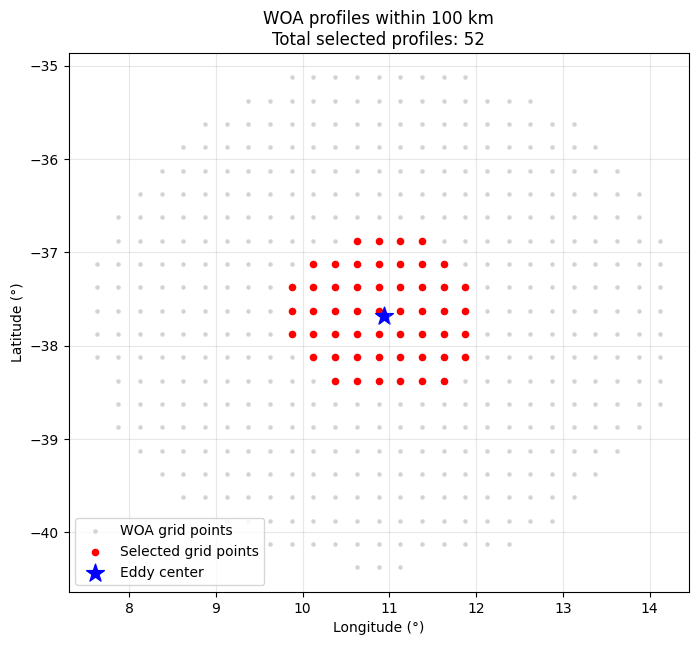

In [30]:
# Eddy radius (km)
eddy_radius = 100

lon = np.array(tlon_woa[:])
lat = np.array(tlat_woa[:])

lon2d, lat2d = np.meshgrid(lon, lat)

# Calculate distance from eddy center
lat_dist = (lat2d - eddy_lat) * 111.0
lon_dist = (lon2d - eddy_lon) * 111.0 * np.cos(np.deg2rad(eddy_lat))

distance = np.sqrt(lat_dist**2 + lon_dist**2)

# Read data
temp = np.ma.filled(woa_temp[:], np.nan)
sal = np.ma.filled(woa_sal[:], np.nan)

# Circular mask, keeping only grid points with data (no land / empty cells)
mask = (distance <= eddy_radius) & np.isfinite(temp[0, 0]) & np.isfinite(sal[0, 0])

print(f"Total WOA grid points: {mask.size}")
print(f"Grid points with data within eddy radius: {np.sum(mask)}")

# Select grid points inside the eddy
temp_eddy = temp[..., mask]
sal_eddy = sal[..., mask]
woa_lons_eddy = lon2d[mask]
woa_lats_eddy = lat2d[mask]
# Count valid profiles at each depth
n_temp = np.sum(np.isfinite(temp_eddy), axis=-1)
n_sal = np.sum(np.isfinite(sal_eddy), axis=-1)

# Average over horizontal grid points
temp_profile = np.nanmean(temp_eddy, axis=-1)
sal_profile = np.nanmean(sal_eddy, axis=-1)

# Depth
depth = np.array(td_woa[:])

fig, ax = plt.subplots(figsize=(8, 7))

near = distance <= 3 * eddy_radius        # plot only the neighbourhood, not the whole globe
ax.scatter(lon2d[near], lat2d[near], s=5, color='lightgray',
           label='WOA grid points')

ax.scatter(lon2d[mask], lat2d[mask], s=20,
           color='red', label='Selected grid points')

ax.scatter(eddy_lon, eddy_lat, marker='*',
           color='blue', s=180, label='Eddy center')

ax.set_xlabel('Longitude (°)')
ax.set_ylabel('Latitude (°)')

ax.set_title(
    f'WOA profiles within {eddy_radius} km\n'
    f'Total selected profiles: {np.sum(mask)}'
)

ax.legend()
ax.grid(alpha=0.3)
plt.show()

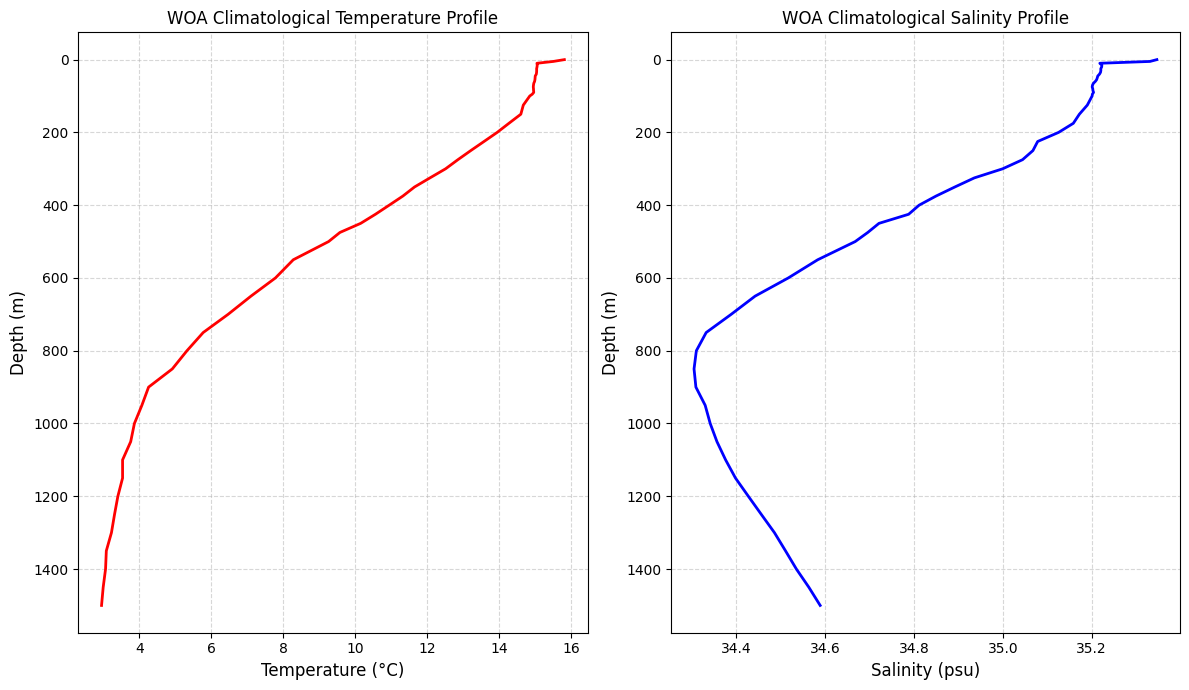

In [31]:
fig, ax = plt.subplots(1, 2, figsize=(12, 7))

# Temperature profile
ax[0].plot(temp_profile.squeeze(), depth, color='red', linewidth=2)
ax[0].set_xlabel('Temperature (°C)', fontsize=12)
ax[0].set_ylabel('Depth (m)', fontsize=12)
ax[0].set_title('WOA Climatological Temperature Profile')
ax[0].invert_yaxis()
ax[0].grid(True, linestyle='--', alpha=0.5)

# Salinity profile
ax[1].plot(sal_profile.squeeze(), depth, color='blue', linewidth=2)
ax[1].set_xlabel('Salinity (psu)', fontsize=12)
ax[1].set_ylabel('Depth (m)', fontsize=12)
ax[1].set_title('WOA Climatological Salinity Profile')
ax[1].invert_yaxis()
ax[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

60 casts used


/Users/emmagurcan/Documents/France/ENS/Speich/WHIRLS/analysis/tools_eg.py:1160: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pc = ax.pcolormesh(xkm, p, data, cmap=cmap, shading="nearest",


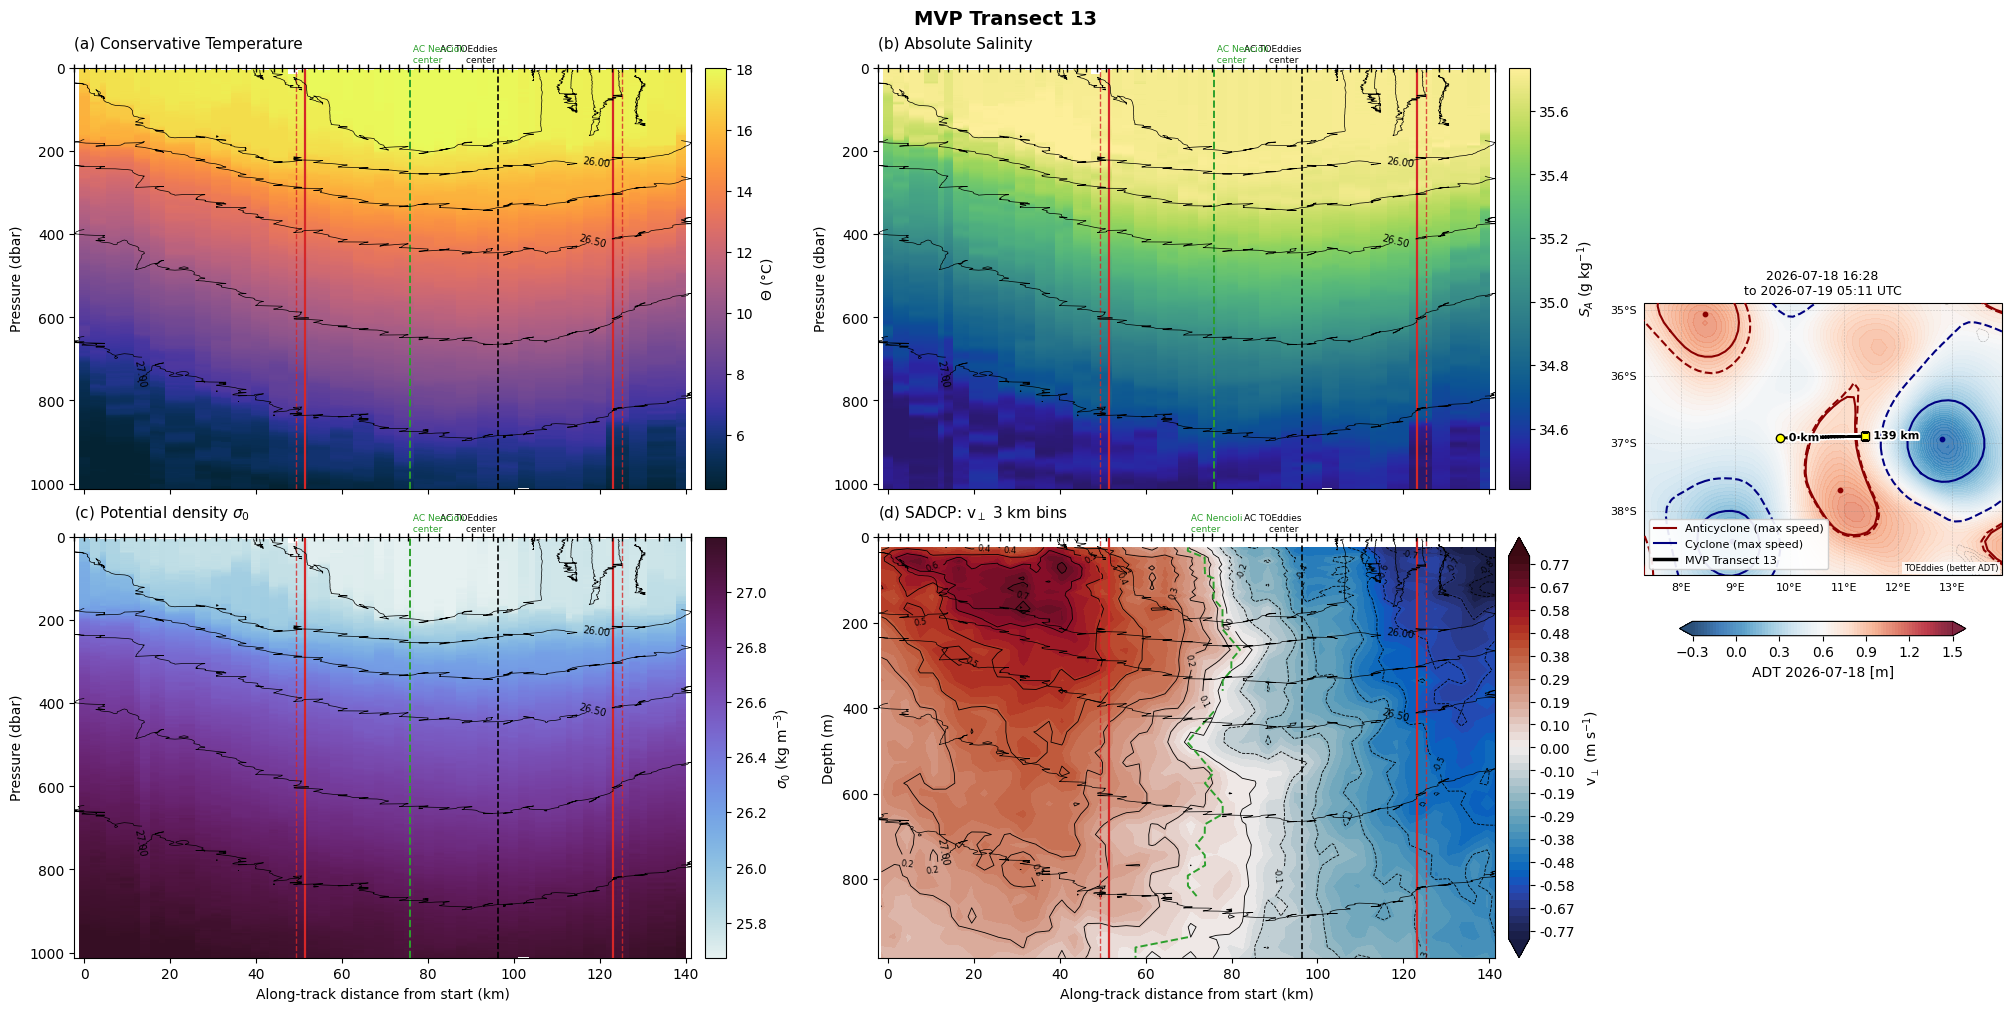

In [32]:
# ---------------- SADCP for zeta (PV) ----------------
ds = sadcp_tr                      # ADCP subset for this transect (sadcp_mvp is ~1 GB, not needed)
zdim = ds["depth"].dims[0]
u = ds["UVEL_ADCP_CORTIDE"].transpose("time", zdim).values
v = ds["VVEL_ADCP_CORTIDE"].transpose("time", zdim).values
pg = ds["PGOOD_ADCP"].transpose("time", zdim).values

u[pg < 50] = np.nan
v[pg < 50] = np.nan

args = [ssh, eddy_files, transect, eddy_source, adt_ticks, date, levels]
invert_x = True
if transect == "Transect 13" or transect == "Transect 14":
    sadcp_mvp_processed["u"] = -sadcp_mvp_processed["u"]
    sadcp_mvp_processed["v"] = -sadcp_mvp_processed["v"]
    invert_x = False
# ---------------- map + Theta / S_A / sigma0 ----------------
sec, fig, axs = process_transect(
    mvp_trans, adcp=sadcp_mvp_processed, cast_col="CAST",
    map_draw=draw_background,      # map_extent=extent  -> whole region instead of zoom
    map_args = args,
    title=f"MVP {transect}",
    eddy=edds,
    savepath=out_dir + f"{transect}_section_hydro_adcp",
    flip_x = invert_x,
    vel_lim = 0.8)
plt.show()

In [33]:
def determine_sigma(S, T, press, lon, lat):
    # Convert practical salinity to absolute salinity
    SA = gsw.SA_from_SP(S, press, lon, lat)  # Longitude and Latitude needed

    # Convert in situ temperature to conservative temperature
    CT = gsw.CT_from_t(SA, T, press)

    # Calculate in situ density (kg/m³)
    rho = gsw.rho(SA, CT, press)

    # Calculate potential density anomaly referenced to 0 dbar
    sigma0 = gsw.sigma0(SA, CT)  # Potential density anomaly (kg/m³ - 1000)

    return sigma0



In [34]:
# Eddy radius (km)
eddy_radius = 100

lon = np.array(tlon_woa[:])
lat = np.array(tlat_woa[:])

lon2d, lat2d = np.meshgrid(lon, lat)

# Calculate distance from eddy center
lat_dist = (lat2d - eddy_lat) * 111.0
lon_dist = (lon2d - eddy_lon) * 111.0 * np.cos(np.deg2rad(eddy_lat))

distance = np.sqrt(lat_dist**2 + lon_dist**2)

# Read data
temp = np.ma.filled(woa_temp[:], np.nan)
sal = np.ma.filled(woa_sal[:], np.nan)

# Circular mask, keeping only grid points with data (no land / empty cells)
mask = (distance <= eddy_radius) & np.isfinite(temp[0, 0]) & np.isfinite(sal[0, 0])

print(f"Total WOA grid points: {mask.size}")
print(f"Grid points with data within eddy radius: {np.sum(mask)}")

# Select grid points inside the eddy
temp_eddy = temp[..., mask]
sal_eddy = sal[..., mask]
woa_lons_eddy = lon2d[mask]
woa_lats_eddy = lat2d[mask]
# Count valid profiles at each depth
n_temp = np.sum(np.isfinite(temp_eddy), axis=-1)
n_sal = np.sum(np.isfinite(sal_eddy), axis=-1)

# Average over horizontal grid points
temp_profile = np.nanmean(temp_eddy, axis=-1)
sal_profile = np.nanmean(sal_eddy, axis=-1)

# one position for the averaged profile
woa_lon_ref = np.mean(woa_lons_eddy)
woa_lat_ref = np.mean(woa_lats_eddy)

depth = np.array(td_woa[:])                  # plain array, not a netCDF masked variable
temp_profile = np.squeeze(temp_profile)      # (1, 57) -> (57,)  (the leading 1 is the time axis)
sal_profile = np.squeeze(sal_profile)

woa_press = gsw.p_from_z(-depth, woa_lat_ref)
sigma_woa = determine_sigma(sal_profile, temp_profile, woa_press, woa_lon_ref, woa_lat_ref)

Total WOA grid points: 1036800
Grid points with data within eddy radius: 52


In [35]:
# ---------------- anomaly functions ----------------
def woa_reference(tref, sref, depth_woa, lon_woa, lat_woa):
    """
    Averaged WOA profile -> reference profile in the SAME variables as the MVP section.
    tref, sref : t_an (in-situ T) and s_an (practical S) averaged over the selected points
    depth_woa  : WOA depth levels (m, positive)
    lon_woa, lat_woa : one position for the averaged profile
    Returns dict(p, CT, SA, sig0) on the WOA levels that have data.
    """
    depth_woa = np.asarray(depth_woa, float)
    tref, sref = np.squeeze(tref), np.squeeze(sref)
    woa_press = gsw.p_from_z(-depth_woa, lat_woa)
    SA = gsw.SA_from_SP(sref, woa_press, lon_woa, lat_woa)
    CT = gsw.CT_from_t(SA, tref, woa_press)
    sigma_woa = gsw.sigma0(SA, CT)
    ok = np.isfinite(SA) & np.isfinite(CT)
    return dict(p=woa_press[ok], CT=CT[ok], SA=SA[ok], sig0=sigma_woa[ok])


def interp_on_rho(sigma, var, ind_rho):
    """var(sigma) -> var on the density levels ind_rho (NaN outside the sigma range).
    Sorted and de-duplicated in sigma (np.interp needs increasing x)."""
    ok = np.isfinite(sigma) & np.isfinite(var)
    if ok.sum() < 2:
        return np.full(len(ind_rho), np.nan)
    order = np.argsort(sigma[ok])
    s, idx = np.unique(sigma[ok][order], return_index=True)
    v = var[ok][order][idx]
    if s.size < 2:
        return np.full(len(ind_rho), np.nan)
    return np.interp(ind_rho, s, v, left=np.nan, right=np.nan)


def anom(ref, sec, var_name="temp", pas=0.01):
    """
    Anomalies of the MVP section relative to the WOA reference profile.
      temp / sal : on isopycnals (Barabinot et al. 2025, eq. 1-2):
                   dT(sigma) = T(sigma) - T*(sigma), then put back at the pressure of
                   that isopycnal in each cast.
      dens       : at constant pressure, sigma0 - sigma0*(p).
    ref : from woa_reference.  sec : from process_transect (p, CT, SA, sig0).
    Returns Anom with the same shape as sec["CT"] (pressure x cast), so it is plotted
    exactly like the Theta / S_A / sigma0 panels.
    """
    p = sec["p"]
    sigma_grid = sec["sig0"]
    len_section = sigma_grid.shape[1]

    if var_name in ["density", "dens"]:
        sigma_ref = np.interp(p, ref["p"], ref["sig0"], left=np.nan, right=np.nan)
        return sigma_grid - sigma_ref[:, None]

    if var_name in ["temperature", "temp"]:
        ref_profile, var_grid = ref["CT"], sec["CT"]
    elif var_name in ["salinity", "sal"]:
        ref_profile, var_grid = ref["SA"], sec["SA"]
    else:
        raise ValueError(f"var_name must be temp, sal or dens, not {var_name!r}")

    ind_rho = np.arange(22, 28, pas)
    ref_interp = interp_on_rho(ref["sig0"], ref_profile, ind_rho)

    Anom = np.full(sigma_grid.shape, np.nan)
    for i in range(len_section):
        var_interp = interp_on_rho(sigma_grid[:, i], var_grid[:, i], ind_rho)
        Anom_rho = var_interp - ref_interp                      # anomaly on each isopycnal
        depT = interp_on_rho(sigma_grid[:, i], p, ind_rho)      # pressure of each isopycnal here

        good = np.isfinite(Anom_rho) & np.isfinite(depT)
        if good.sum() < 2:
            continue
        order = np.argsort(depT[good])
        d, idx = np.unique(depT[good][order], return_index=True)
        a = Anom_rho[good][order][idx]
        if d.size < 2:
            continue
        Anom[:, i] = np.interp(p, d, a, left=np.nan, right=np.nan)
    return Anom


In [36]:
# ---------------- figure ----------------
def plot_anomaly_section_with_map(sec, adcp, anoms, map_draw=None, map_args=None, title="",
                                  pmax=None, sig_levels=None, map_extent=None, map_pad=(2.5, 2.0),
                                  vel_lim=None, anom_lims=None, edd=None, savepath=None,
                                  flip_x=True, woa_lon=None, woa_lat=None):
    """
    Same layout as plot_section_with_map, with anomalies instead of Theta / S_A / sigma0:
                (a) Theta anomaly      (b) S_A anomaly
                (c) sigma0 anomaly     (d) SADCP cross-track velocity
            small map on the right.
    anoms     : dict(CT=..., SA=..., sig0=...) from anom(), same shape as sec["CT"].
    anom_lims : optional dict(CT=..., SA=..., sig0=...) of symmetric colour limits;
                default = 99th percentile of |anomaly|.
    Everything else is as in plot_section_with_map.
    """
    import matplotlib.patheffects as pe
    from matplotlib.gridspec import GridSpec
    try:
        import cartopy.crs as ccrs
        import cartopy.feature as cfeature
    except ImportError:
        ccrs = None

    anom_lims = anom_lims or {}
    lon, lat = sec["lon"], sec["lat"]
    xkm, p = sec["x"] / 1e3, sec["p"]
    if map_extent is None:
        map_extent = [np.nanmin(lon) - map_pad[0], np.nanmax(lon) + map_pad[0],
                      np.nanmin(lat) - map_pad[1], np.nanmax(lat) + map_pad[1]]
    sig_levels = sig_levels if sig_levels is not None else np.arange(
        np.floor(np.nanmin(sec["sig0"]) * 4) / 4, np.nanmax(sec["sig0"]), 0.25)

    fig = plt.figure(figsize=(20, 10), constrained_layout=True)
    outer = GridSpec(1, 2, figure=fig, width_ratios=[4, 1])
    gs_sec = outer[0].subgridspec(2, 2)
    gs_map = outer[1].subgridspec(2, 1, height_ratios=[1, 0.6])

    ax0 = fig.add_subplot(gs_sec[0, 0])
    axs = [ax0,
           fig.add_subplot(gs_sec[0, 1], sharex=ax0),
           fig.add_subplot(gs_sec[1, 0], sharex=ax0),
           fig.add_subplot(gs_sec[1, 1], sharex=ax0)]

    # ---- (a)-(c) anomalies: diverging colours, white = 0 ----
    specs = [("CT", r"$\Delta\Theta$ (°C)", r"(a) $\Theta$ anomaly on isopycnals"),
             ("SA", r"$\Delta S_A$ (g kg$^{-1}$)", r"(b) $S_A$ anomaly on isopycnals"),
             ("sig0", r"$\Delta\sigma_0$ (kg m$^{-3}$)", r"(c) $\sigma_0$ anomaly at constant pressure")]
    for ax, (key, lab, ttl) in zip(axs[:3], specs):
        data = anoms[key]
        lim = anom_lims.get(key)
        if lim is None:
            vals = np.abs(data[np.isfinite(data)])
            lim = np.nanpercentile(vals, 99) if vals.size else 1.0
        pc = ax.pcolormesh(xkm, p, data, cmap=cmocean.cm.balance, shading="nearest",
                           vmin=-lim, vmax=lim)
        fig.colorbar(pc, ax=ax, label=lab, pad=0.01)
        ax.set_title(ttl, loc="left", fontsize=11, pad=14)

    # --- (d) SADCP cross-track velocity (unchanged) ---
    axc = axs[3]
    a_lon, a_lat, z, u, v = adcp["lon"], adcp["lat"], adcp["z"], adcp["u"], adcp["v"]
    s_m, _ = along_track_x(np.asarray(a_lon), np.asarray(a_lat),
                           sec["lon"][0], sec["lat"][0], sec["xdir"])
    s = s_m / 1e3
    ex = sec["xdir"]
    vn = -u * ex[1] + v * ex[0]        # positive = to the LEFT of the 0 km -> end direction

    edges = np.arange(np.floor(np.nanmin(s)), np.ceil(np.nanmax(s)) + DS_KM, DS_KM)
    xg, V, _ = bin_columns(s, vn, edges)
    V = fill_z_gaps(V, z)

    if vel_lim is None:
        vals = np.abs(V.ravel())
        vlim = max(0.1, np.round(np.nanpercentile(vals[np.isfinite(vals)], 98) * 10) / 10)
    else:
        vlim = vel_lim
    fill_lev = np.linspace(-vlim, vlim, N_FILL + 1)
    cf = axc.contourf(xg, z, V.T, levels=fill_lev, cmap=cmocean.cm.balance, extend="both")
    nstep = int(np.ceil(vlim / C_LINE_STEP)) + 1
    line_lev = np.round(np.arange(-nstep, nstep + 1) * C_LINE_STEP, 3)
    cs = axc.contour(xg, z, V.T, levels=line_lev, colors="k", linewidths=0.6)
    axc.clabel(cs, cs.levels, fmt="%.1f", fontsize=6, inline=True, inline_spacing=2)
    cbc = fig.colorbar(cf, ax=axc, pad=0.01)
    cbc.set_ticks(fill_lev[1::3])
    cbc.ax.set_yticklabels([f"{0.0 if abs(t) < 1e-9 else t:.2f}" for t in fill_lev[1::3]])
    cbc.set_label(r"v$_\perp$ (m s$^{-1}$)")
    axc.set_title(fr"(d) SADCP: v$_\perp$ {DS_KM:.0f} km bins", loc="left", fontsize=11, pad=14)

    edds = [edd] if isinstance(edd, dict) else list(edd or [])
    if edds:
        mark_eddies_on_sections(axs, sec, z, a_lon, a_lat, u, v, edds)

    for ax in axs:
        cs = ax.contour(xkm, p, sec["sig0"], levels=sig_levels, colors="k", linewidths=0.5)
        ax.clabel(cs, cs.levels[::2], fontsize=7, fmt="%.2f")
        ax.plot(xkm, np.zeros_like(xkm), "|", color="k", ms=6, clip_on=False)

    p_bot = pmax if pmax else np.nanmax(p)
    z_bot = pmax if pmax else np.nanmax(z)
    for ax in axs[:3]:
        ax.set_ylim(p_bot, 0)
        ax.set_ylabel("Pressure (dbar)")
    axc.set_ylim(z_bot, 0)
    axc.set_ylabel("Depth (m)")

    axs[0].set_xlim(np.nanmin(xkm), np.nanmax(xkm))
    if flip_x:
        axs[0].invert_xaxis()
    for ax in axs[:2]:
        ax.tick_params(labelbottom=False)
    for ax in axs[2:]:
        ax.tick_params(labelbottom=True)
        ax.set_xlabel("Along-track distance from start (km)")

    # ======================= map (small, right) =======================
    if ccrs is not None:
        crs = ccrs.PlateCarree()
        proj = ccrs.Mercator(central_longitude=np.mean(map_extent[:2]))
        axm = fig.add_subplot(gs_map[0], projection=proj)
        axm.set_extent(map_extent, crs=crs)
        tr = dict(transform=crs)
    else:
        crs, tr = None, {}
        axm = fig.add_subplot(gs_map[0])
        axm.set_xlim(map_extent[:2]); axm.set_ylim(map_extent[2:])
        axm.set_aspect(1 / np.cos(np.deg2rad(np.mean(map_extent[2:]))))

    if map_draw is not None:
        map_draw(axm, crs, *(map_args or []))

    if ccrs is not None:
        axm.add_feature(cfeature.LAND, facecolor="0.8", zorder=50)
        axm.coastlines(resolution="50m", linewidth=0.6, zorder=51)
        gl = axm.gridlines(crs=crs, draw_labels=True, linewidth=0.4, color="0.5",
                           alpha=0.4, linestyle="--")
        gl.top_labels = gl.right_labels = False
        gl.xlabel_style = gl.ylabel_style = {"size": 8}
    else:
        axm.grid(lw=0.4, alpha=0.4, ls="--")
        axm.tick_params(labelsize=8)

    halo = [pe.Stroke(linewidth=4.5, foreground="white"), pe.Normal()]
    axm.plot(lon, lat, "-", color="k", lw=2, path_effects=halo, zorder=100, **tr)
    if woa_lon is not None and len(woa_lon):
        axm.scatter(woa_lon, woa_lat, s=6, color="orange", edgecolor="k", linewidth=0.2,
                    zorder=101, **tr)
    for i, lab in [(0, "0 km"), (-1, f"{xkm[-1]:.0f} km")]:
        axm.plot(lon[i], lat[i], marker="o" if i == 0 else "s", ms=6, mfc="yellow",
                 mec="k", mew=1, zorder=102, **tr)
        axm.annotate(lab, (lon[i], lat[i]), xytext=(6, 0), textcoords="offset points",
                     fontsize=8, fontweight="bold", va="center", zorder=103,
                     path_effects=[pe.withStroke(linewidth=2.5, foreground="white")],
                     xycoords=crs._as_mpl_transform(axm) if crs is not None else "data")
    t0 = sec["time"][0].strftime("%Y-%m-%d %H:%M")
    t1 = sec["time"][-1].strftime("%Y-%m-%d %H:%M")
    axm.set_title(f"{t0}\nto {t1} UTC", fontsize=9)

    fig.suptitle(title, fontsize=14, fontweight="bold")
    if savepath:
        fig.savefig(savepath, dpi=300, bbox_inches="tight")
    return fig, [axm] + axs


CT    anomaly: -0.967 .. +1.243, 78% of the section filled
SA    anomaly: -0.166 .. +0.362, 78% of the section filled
sig0  anomaly: -0.605 .. +0.160, 100% of the section filled


/var/folders/lg/5krm8xnn5xv0smms_psmknp40000gn/T/ipykernel_54797/3679491382.py:54: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pc = ax.pcolormesh(xkm, p, data, cmap=cmocean.cm.balance, shading="nearest",


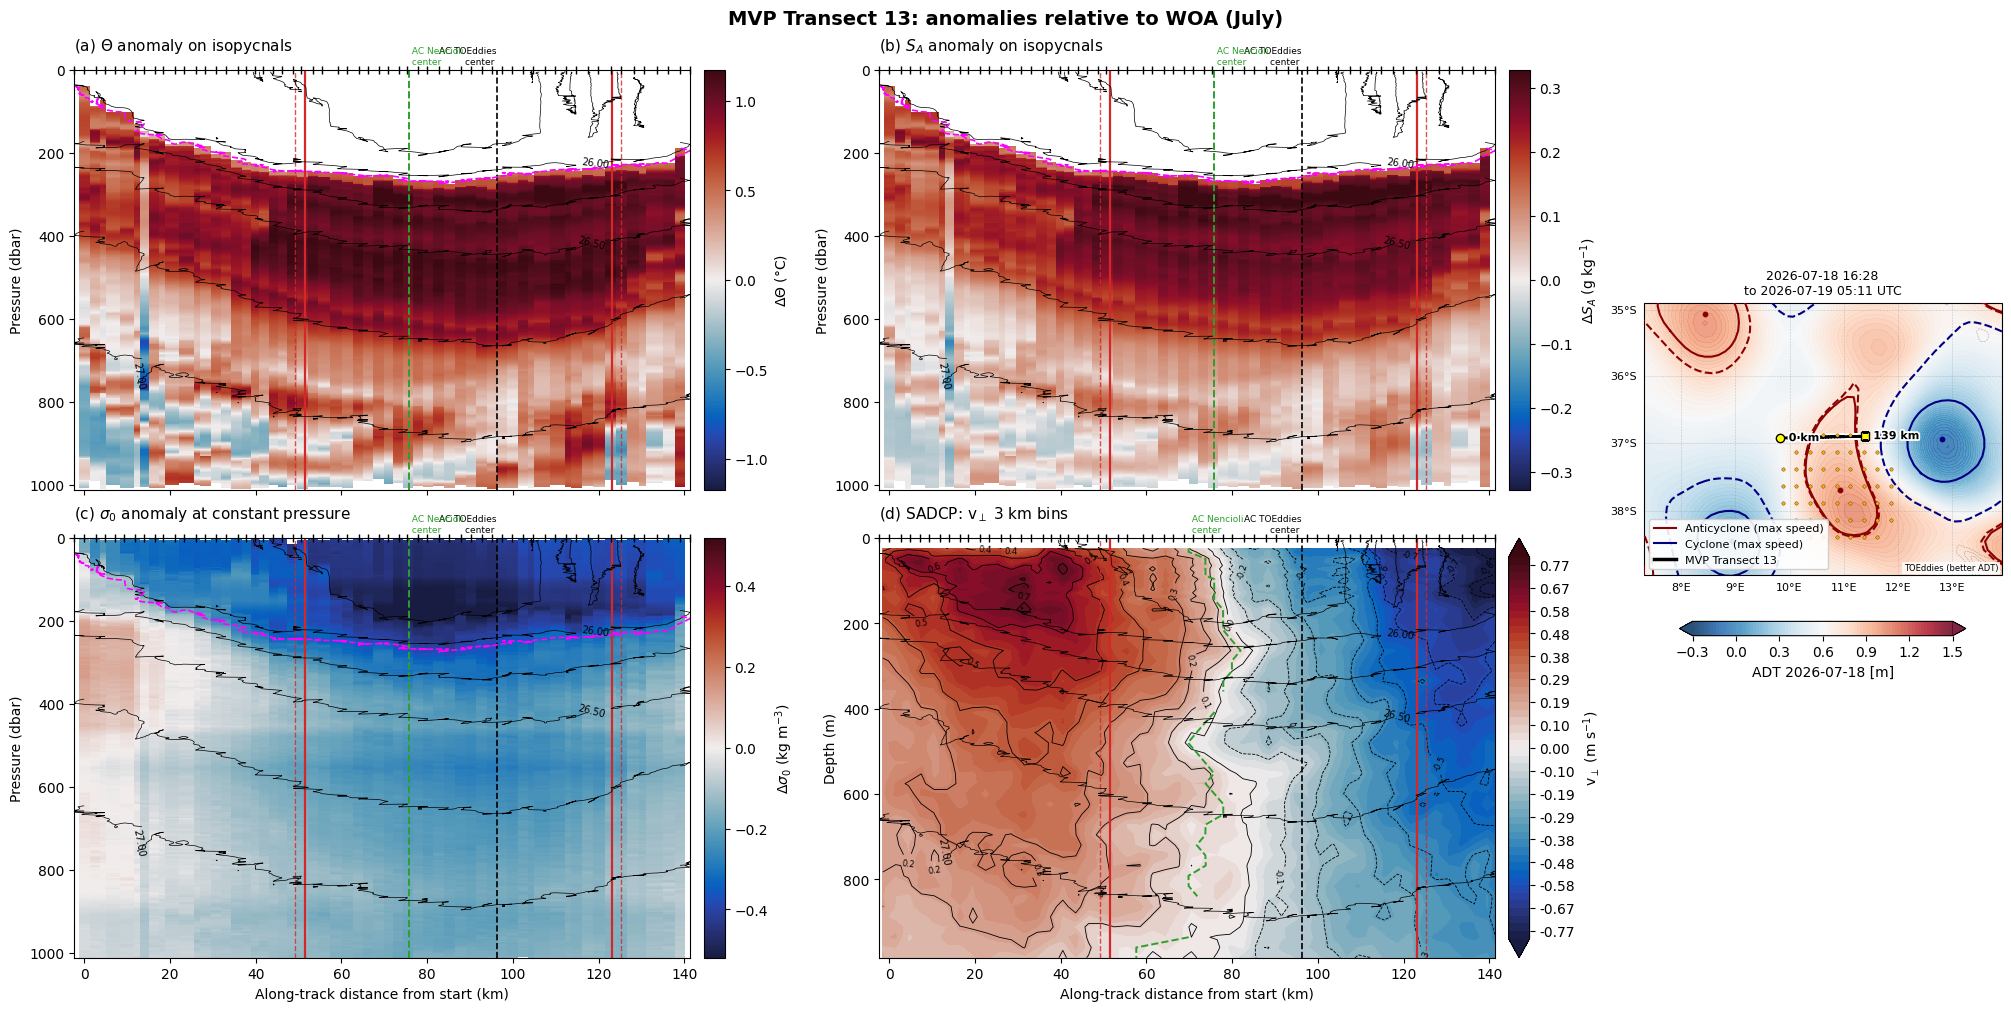

In [37]:
# ---------------- run ----------------
woa_ref = woa_reference(temp_profile, sal_profile, depth, woa_lon_ref, woa_lat_ref)

anoms = dict(CT=anom(woa_ref, sec, "temp"),
             SA=anom(woa_ref, sec, "sal"),
             sig0=anom(woa_ref, sec, "dens"))
sig_min_ref = np.nanmin(woa_ref["sig0"])
too_light = sec["sig0"] < sig_min_ref          # no matching isopycnal in WOA

# for key in ["CT", "SA"]:
#     ref_p = np.interp(sec["p"], woa_ref["p"], woa_ref[key], left=np.nan, right=np.nan)
#     iso_p = sec[key] - ref_p[:, None]          # anomaly at constant pressure
#     anoms[key] = np.where(np.isnan(anoms[key]) & too_light, iso_p, anoms[key])
for k, a in anoms.items():
    print(f"{k:5s} anomaly: {np.nanmin(a):+.3f} .. {np.nanmax(a):+.3f}, "
          f"{np.isfinite(a).mean() * 100:.0f}% of the section filled")
if invert_x:
    sadcp_mvp_processed["u"] = -sadcp_mvp_processed['u']
    sadcp_mvp_processed["v"] = -sadcp_mvp_processed['v']
fig, axs = plot_anomaly_section_with_map(
    sec, sadcp_mvp_processed, anoms,
    map_draw=draw_background, map_args=args,
    title=f"MVP {transect}: anomalies relative to WOA (July)",
    edd=edds, flip_x=invert_x, vel_lim=0.8,
    woa_lon=woa_lons_eddy, woa_lat=woa_lats_eddy,
    savepath=out_dir + f"{transect}_section_anomalies_adcp")
for ax in axs[1:4]:
    ax.contour(sec["x"] / 1e3, sec["p"], sec["sig0"], levels=[sig_min_ref],
               colors="magenta", linewidths=1.2, linestyles="--")
plt.show()


In [38]:
print("lightest WOA sigma0:", np.nanmin(woa_ref["sig0"]).round(3))
print("lightest MVP sigma0:", np.nanmin(sec["sig0"]).round(3))

lightest WOA sigma0: 26.059
lightest MVP sigma0: 25.661
